# Study final reports — locked variants

Reports the four final Experiment 1 variants on the held-out test split,
exactly as locked in the frozen Phase 4 manifest:

- `if:IF-raw:aug_on`
- `ocsvm:SVM-base:aug_on`
- `ae:AE-log:aug_on`
- `ensemble:IF-raw+SVM-base:aug_on` (IF weight 0.7 / OCSVM 0.3)

No refitting, no re-selection: artifacts and thresholds are read from the
frozen manifest. Visuals are saved under `study/final_reports/`.

In [1]:
import json
from pathlib import Path

import joblib
import pandas as pd
from IPython.display import Image, display

from cheatdetect.eval import (
    evaluate_model,
    plot_confusion_matrices,
    plot_pr_curves,
    plot_roc_curves,
)
from cheatdetect.experiments.experiment_1 import runner
from cheatdetect.experiments.experiment_1.config import StudyConfig
from cheatdetect.utils import _find_project_root

FINAL_VARIANTS = [
    "if:IF-raw:aug_on",
    "ocsvm:SVM-base:aug_on",
    "ae:AE-log:aug_on",
    "ensemble:IF-raw+SVM-base:aug_on",
]

REPORT_DIR = _find_project_root() / "study" / "final_reports"
FIGURE_DIR = REPORT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

config = StudyConfig()
study = runner.load_study(config)
run_dir = runner.DEFAULT_RUN_DIR
manifest = json.loads((run_dir / "reporting_manifest.json").read_text())

## Frozen variant selection

In [2]:
entries = {entry["id"]: entry for entry in manifest["primary"]}
missing = [variant for variant in FINAL_VARIANTS if variant not in entries]
if missing:
    raise ValueError(f"Final variants missing from the frozen manifest: {missing}")

pd.DataFrame(
    [
        {
            "id": entry["id"],
            "family": entry["family"],
            "recipe": entry["recipe"],
            "augmented": entry["augmented"],
            "if_weight": entry.get("if_weight"),
            "validation_roc_auc": entry["roc_auc"],
            "threshold": entry["threshold"],
            "fallback_used": entry["threshold_info"]["fallback_used"],
        }
        for entry in (entries[variant] for variant in FINAL_VARIANTS)
    ]
)

,id,family,recipe,augmented,if_weight,validation_roc_auc,threshold,fallback_used
0,if:IF-raw:aug_on,if,IF-raw,True,NaN,0.784723,-0.062151,False
1,ocsvm:SVM-base:aug_on,ocsvm,SVM-base,True,NaN,0.766371,-0.019055,False
2,ae:AE-log:aug_on,ae,AE-log,True,NaN,0.744491,0.360546,False
3,ensemble:IF-raw+SVM-base:aug_on,ensemble,IF-raw+SVM-base,True,0.7,0.794565,0.658771,False


## Test evaluation (frozen thresholds)

In [3]:
raw = study.raw["mixed_test"]
flat_x, sequence_x, y_test = raw.parent, raw.sequences, raw.labels

results = []
for variant in FINAL_VARIANTS:
    entry = entries[variant]
    detector = joblib.load(entry["artifact"])
    X = sequence_x if entry["family"] == "ae" else flat_x
    result = evaluate_model(
        entry["id"], detector.decision_function(X), float(entry["threshold"]), y_test
    )
    result.update(
        {
            "family": entry["family"],
            "recipe": entry["recipe"],
            "if_weight": entry.get("if_weight"),
        }
    )
    results.append(result)

pd.DataFrame(
    [
        {
            "id": result["model"],
            "family": result["family"],
            "recipe": result["recipe"],
            "if_weight": result["if_weight"],
            "threshold": result["threshold"],
            "roc_auc": result["roc_auc"],
            "pr_auc": result["pr_auc"],
            "pr_auc_baseline": result["pr_auc_baseline"],
            "precision": result["precision"],
            "recall": result["recall"],
            "f1": result["f1"],
            "tp": result["tp"],
            "tn": result["tn"],
            "fp": result["fp"],
            "fn": result["fn"],
        }
        for result in results
    ]
).to_csv(REPORT_DIR / "final_metrics.csv", index=False)

display(pd.read_csv(REPORT_DIR / "final_metrics.csv"))

,id,family,recipe,if_weight,threshold,roc_auc,pr_auc,pr_auc_baseline,precision,recall,f1,tp,tn,fp,fn
0,if:IF-raw:aug_on,if,IF-raw,NaN,-0.062151,0.713801,0.750017,0.560109,0.739130,0.663415,0.699229,136,113,48,69
1,ocsvm:SVM-base:aug_on,ocsvm,SVM-base,NaN,-0.019055,0.732344,0.746070,0.560109,0.779762,0.639024,0.702413,131,124,37,74
2,ae:AE-log:aug_on,ae,AE-log,NaN,0.360546,0.631359,0.660721,0.560109,0.709924,0.453659,0.553571,93,123,38,112
3,ensemble:IF-raw+SVM-base:aug_on,ensemble,IF-raw+SVM-base,0.7,0.658771,0.719073,0.758711,0.560109,0.767045,0.658537,0.708661,135,120,41,70


## Per-variant visuals — ROC, PR, confusion matrix

=== if:IF-raw:aug_on ===


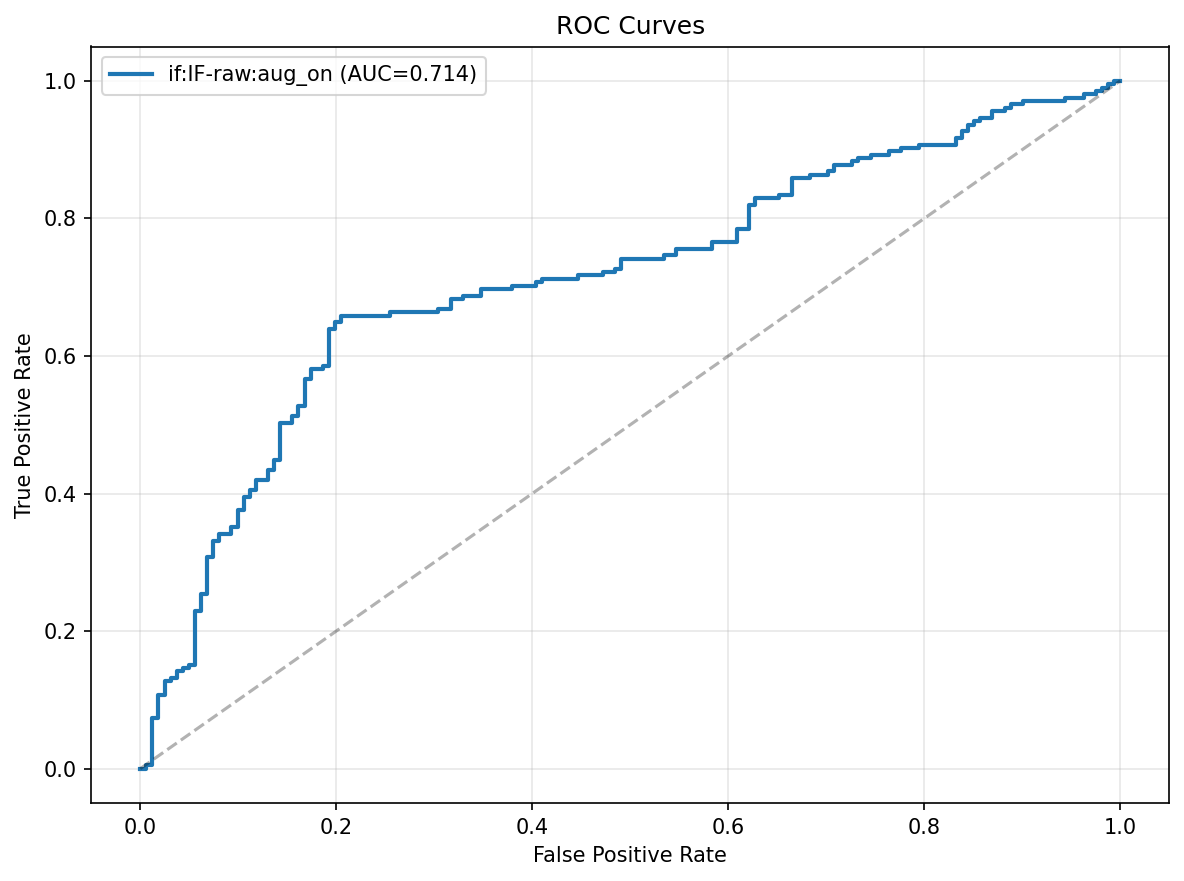

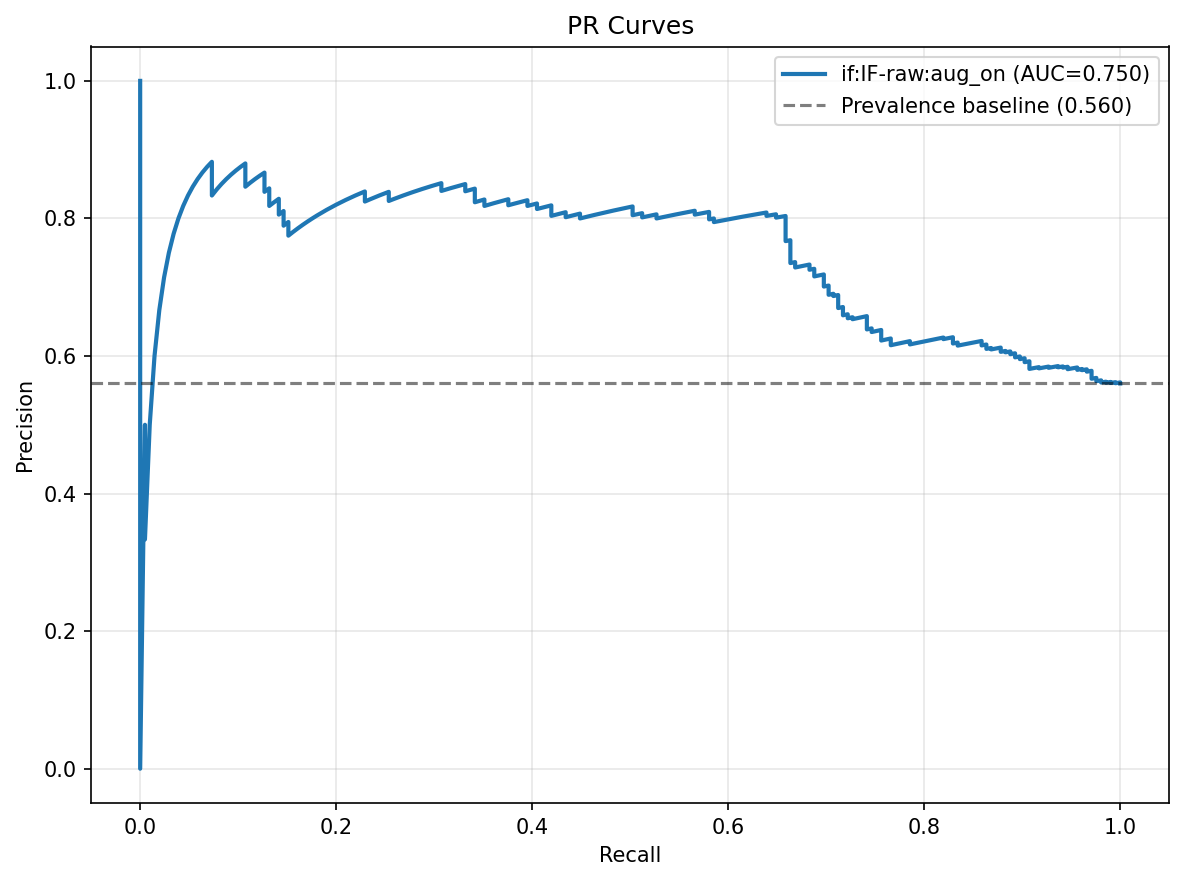

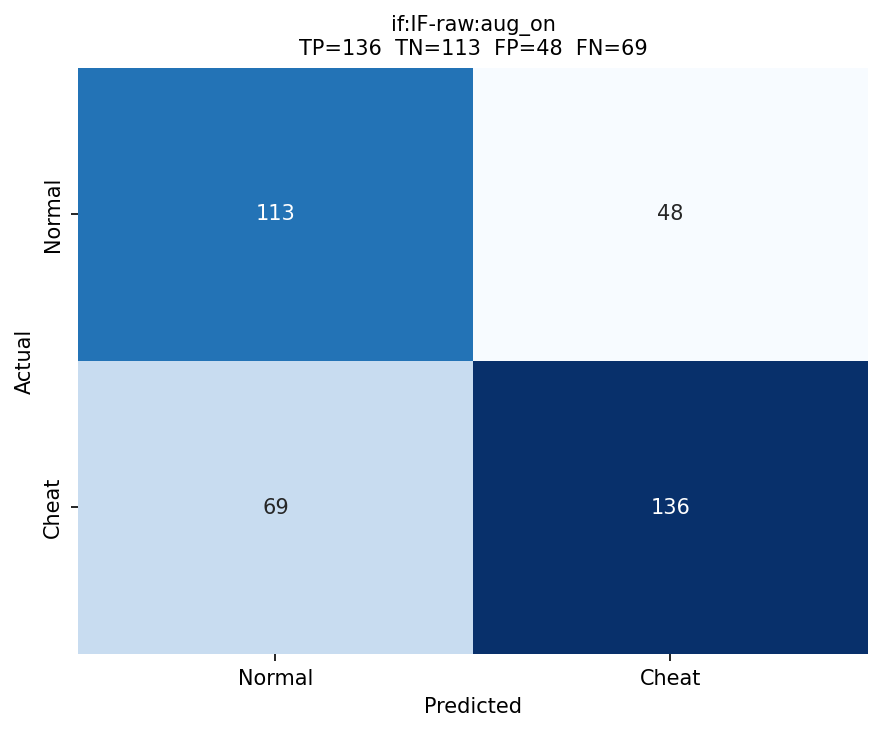

=== ocsvm:SVM-base:aug_on ===


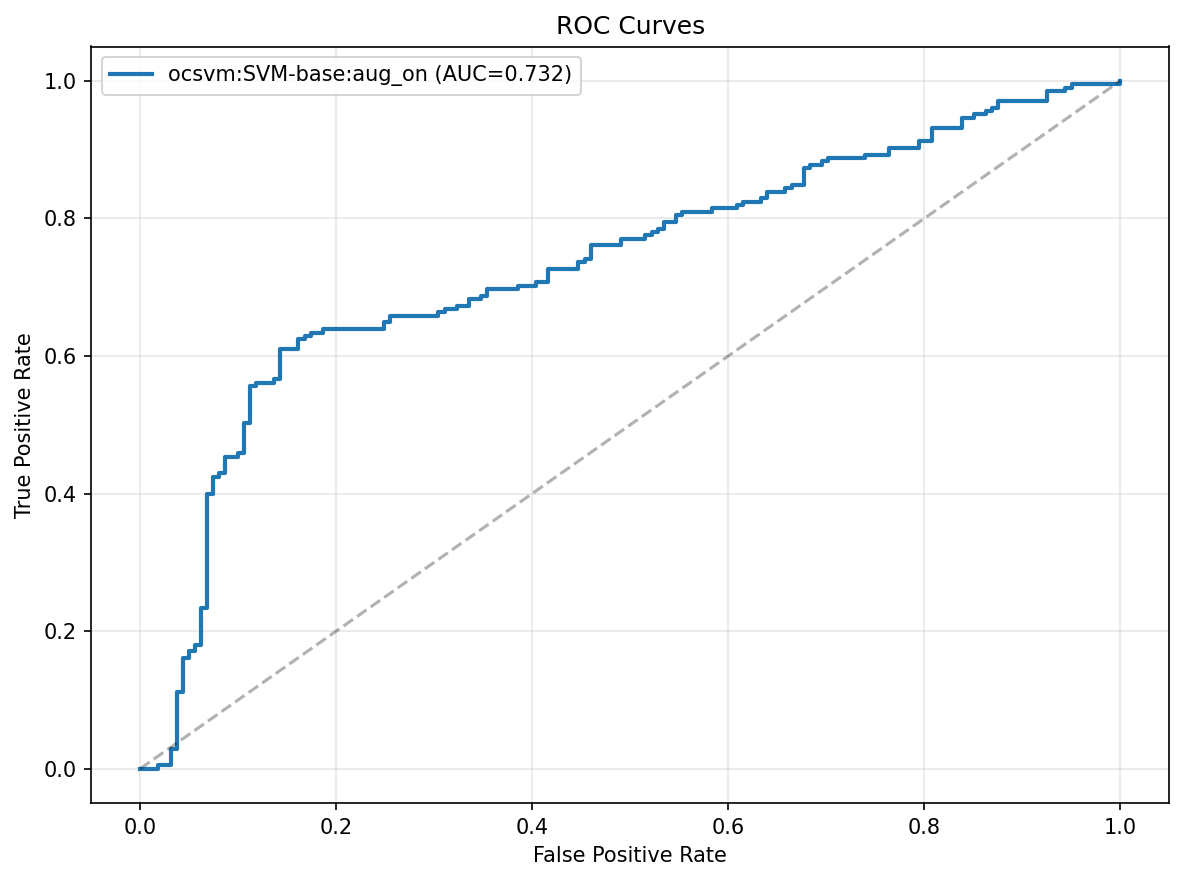

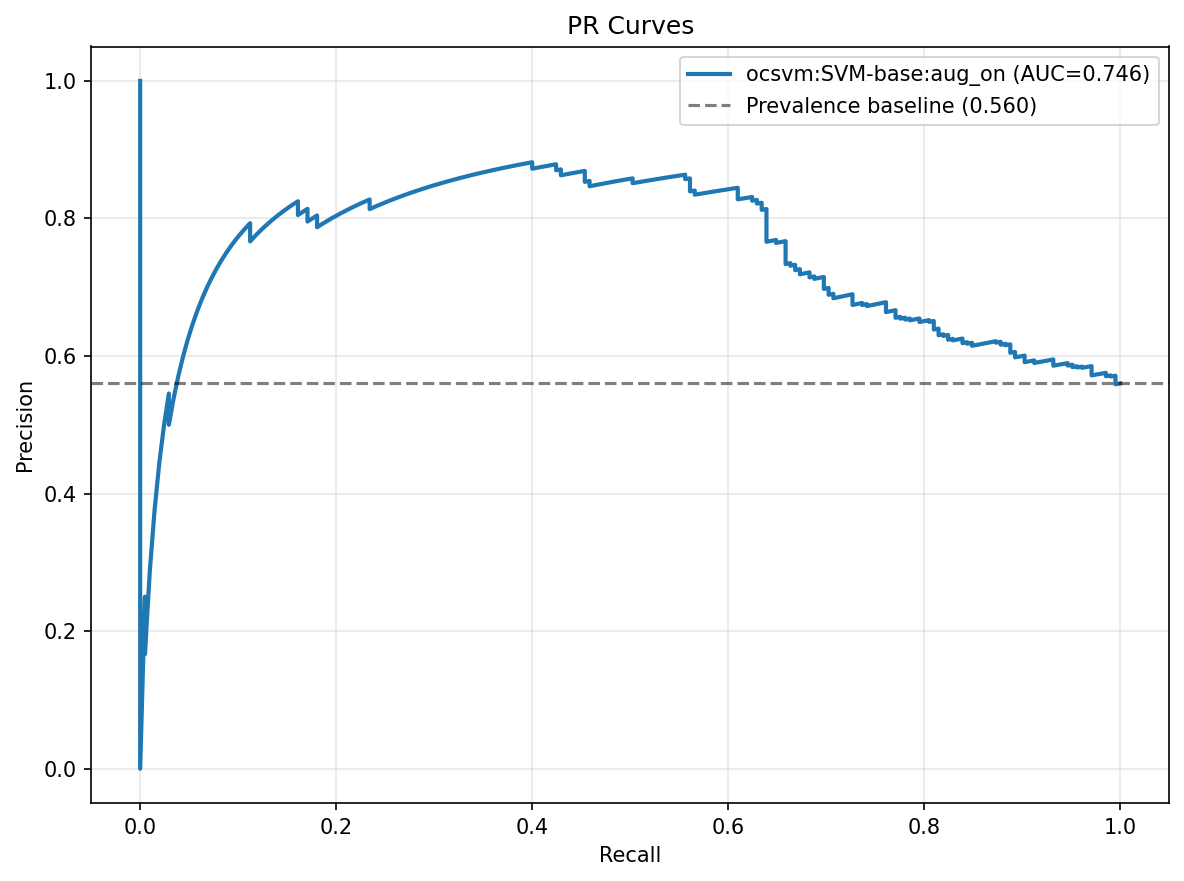

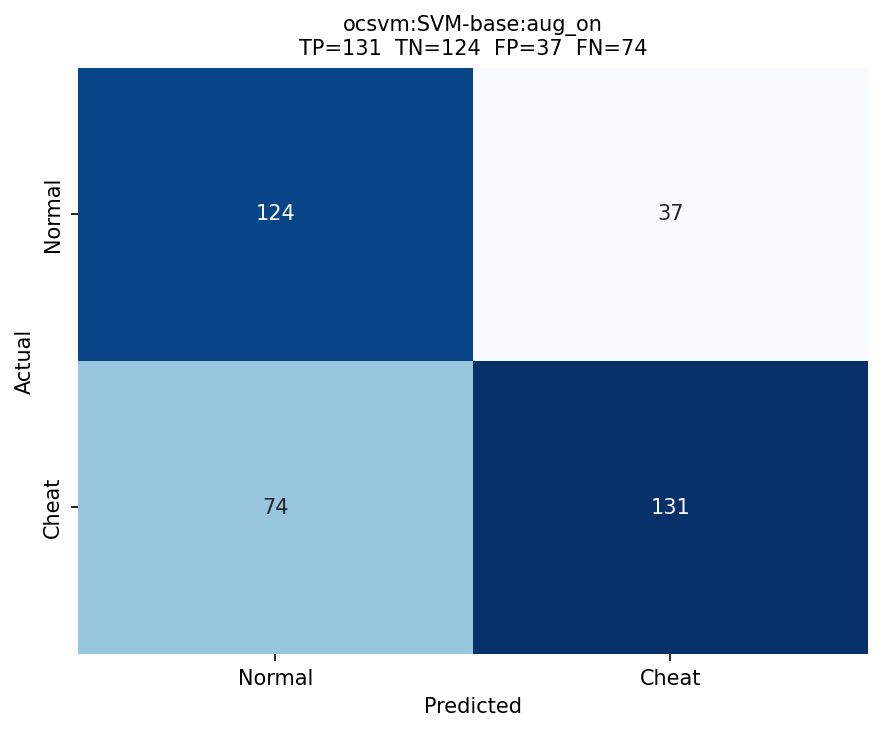

=== ae:AE-log:aug_on ===


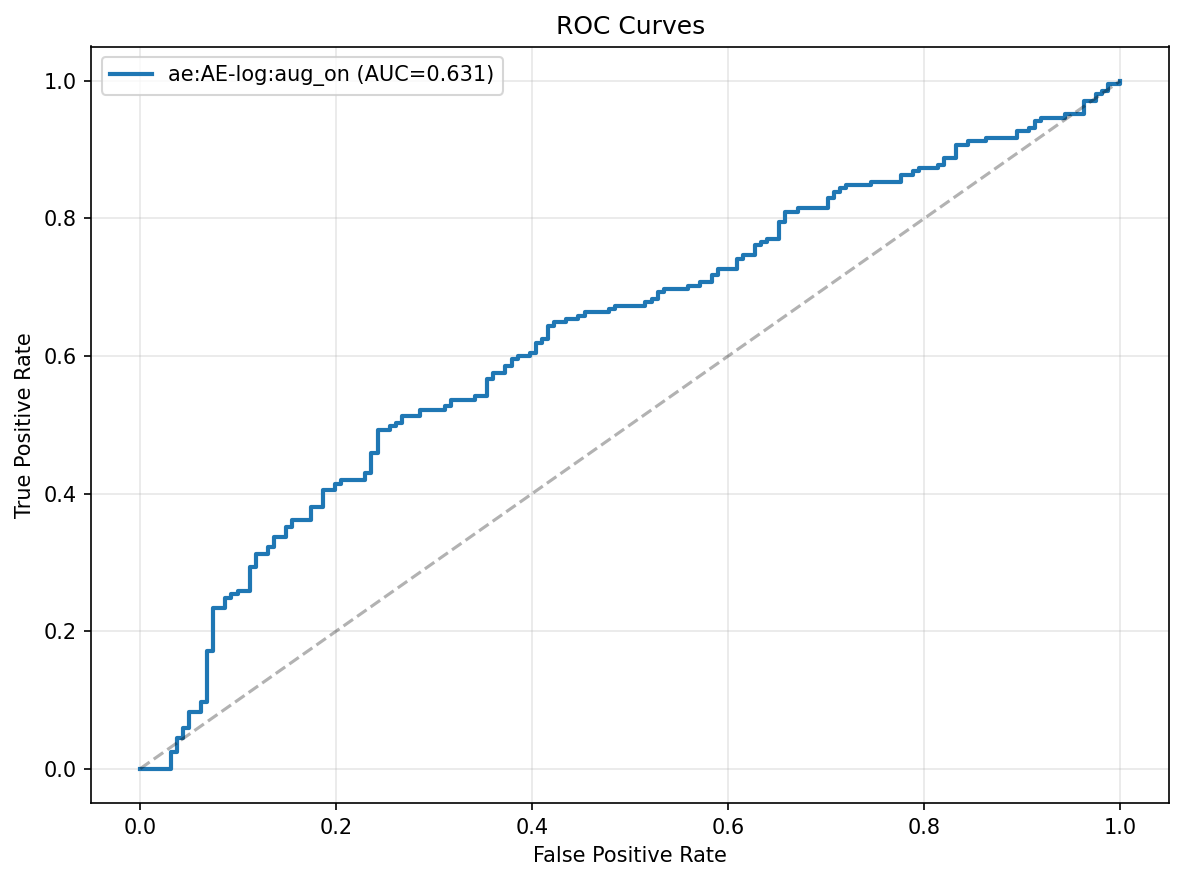

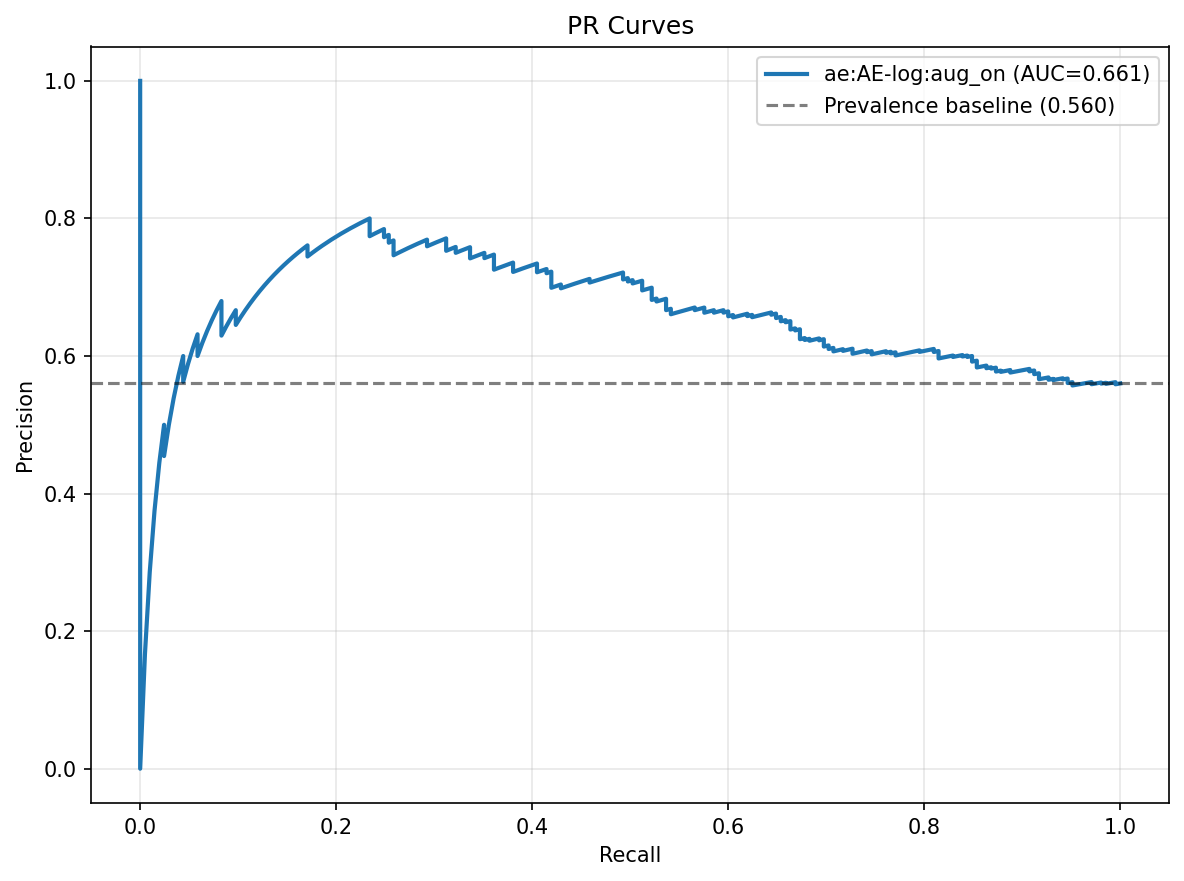

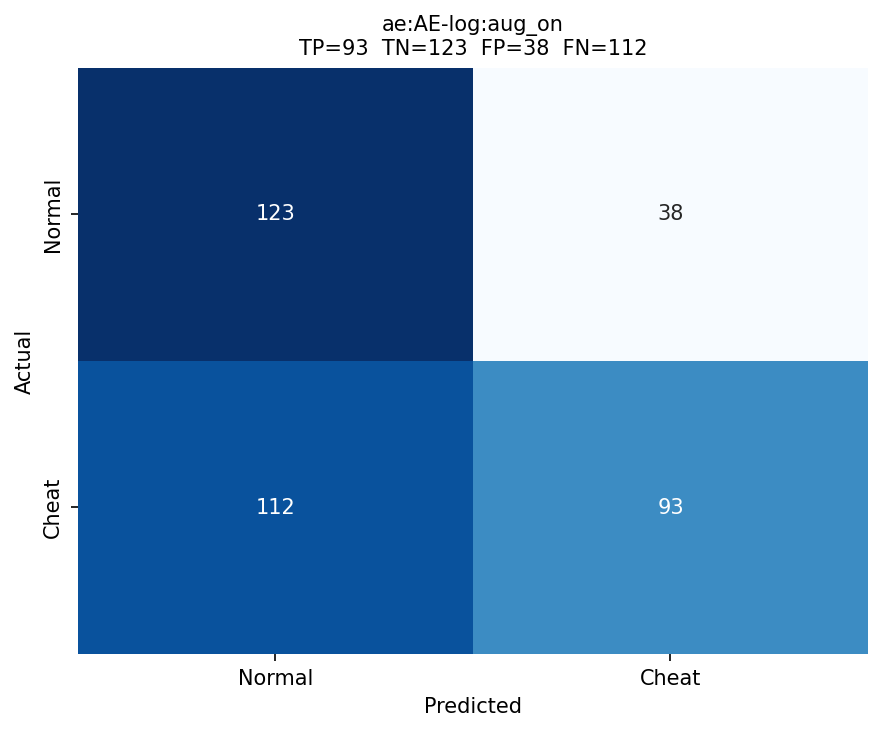

=== ensemble:IF-raw+SVM-base:aug_on ===


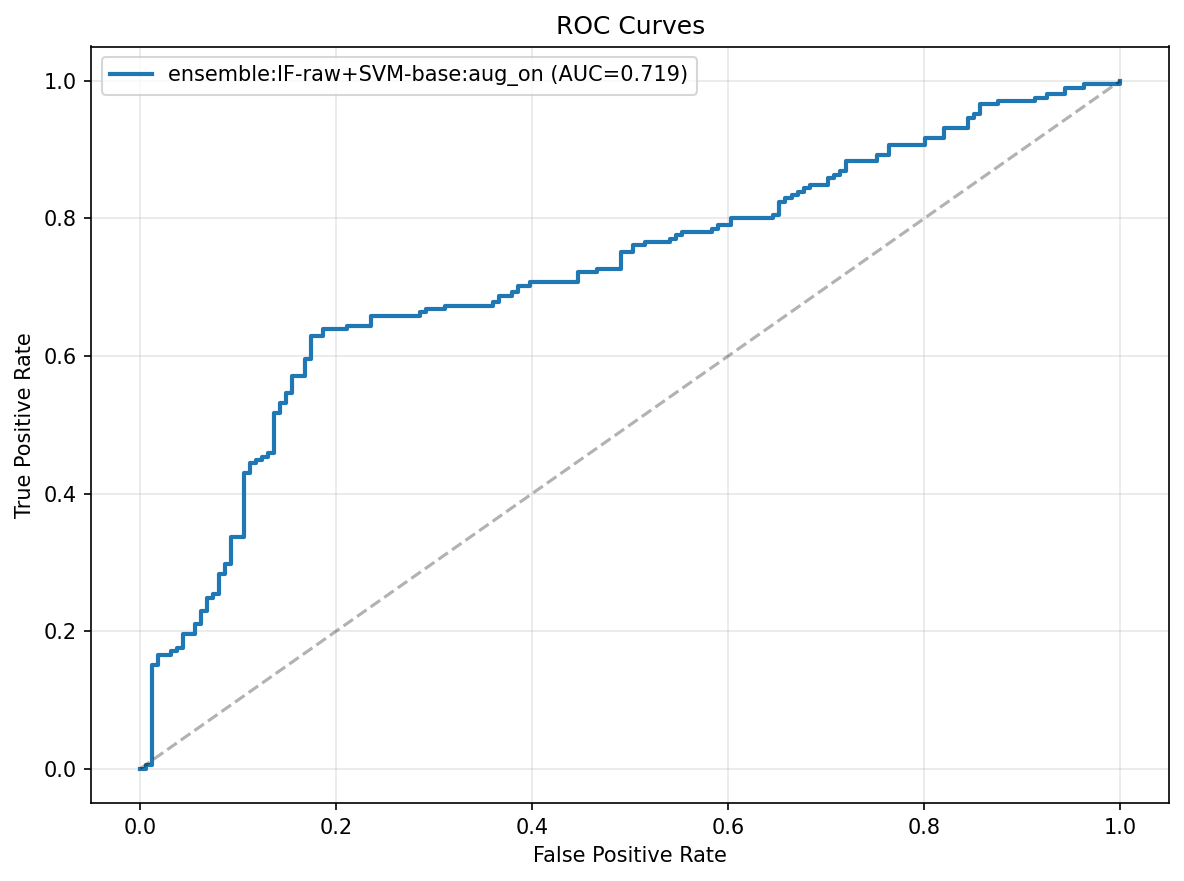

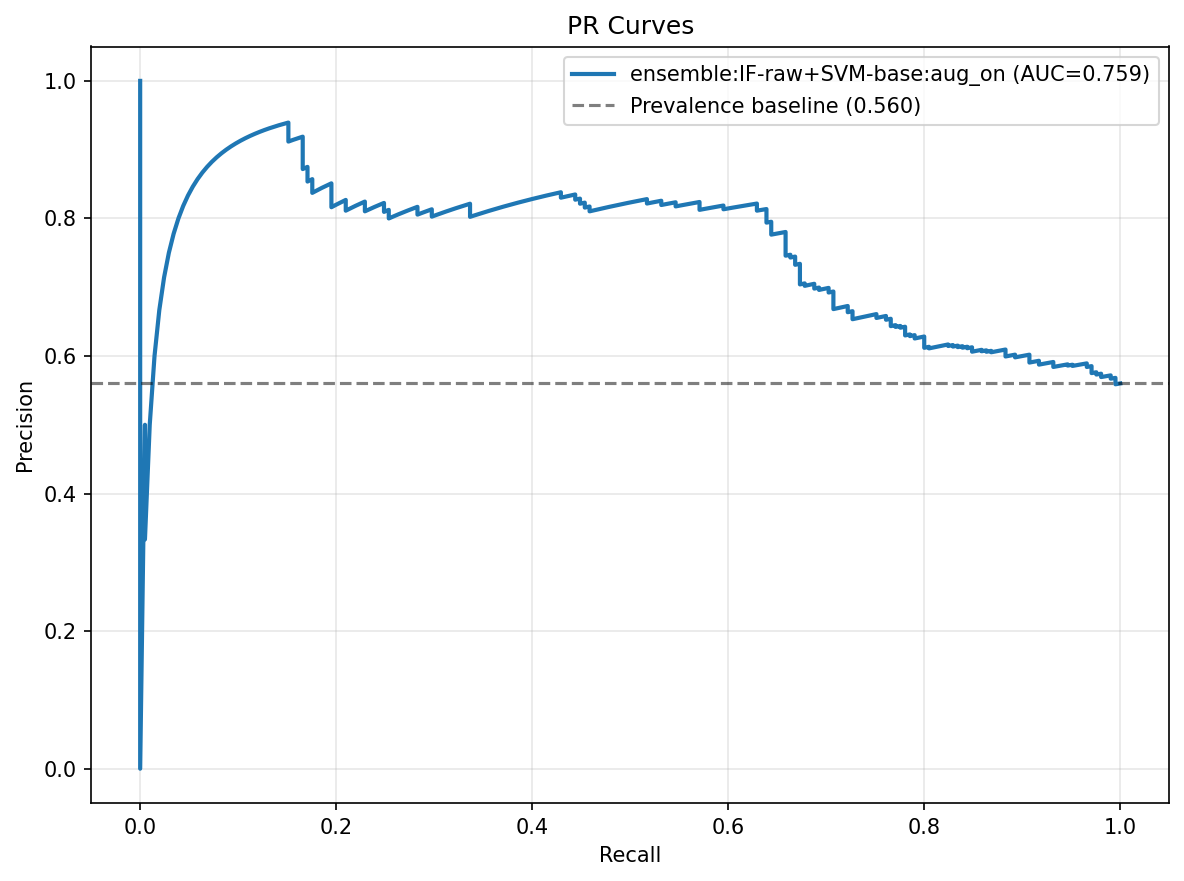

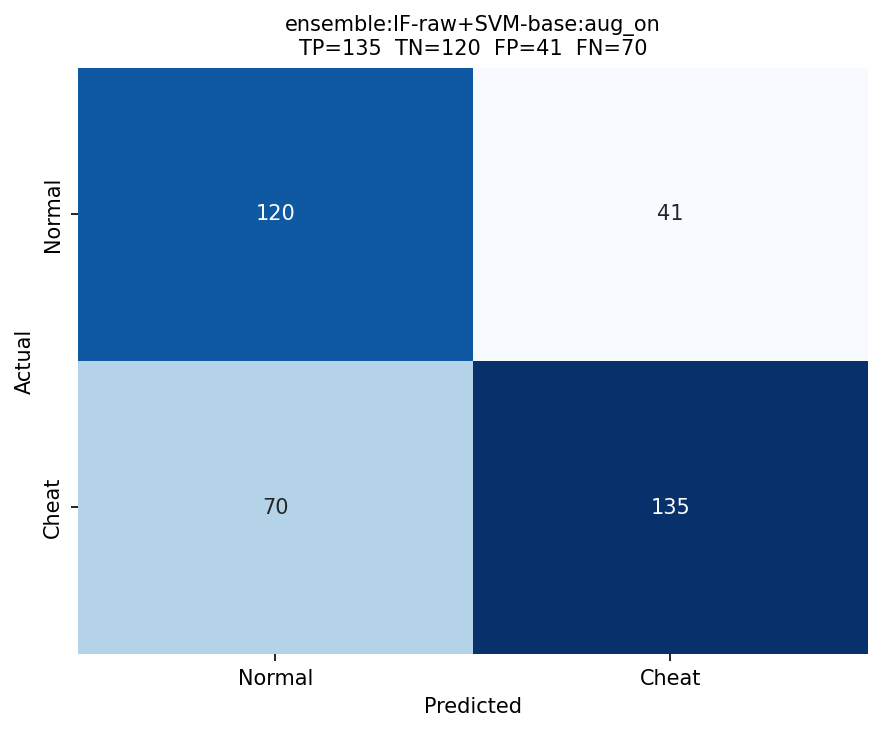

In [4]:
for result in results:
    safe = result["model"].replace(":", "_").replace("+", "_")
    scores = {result["model"]: result["scores"]}
    plot_roc_curves(scores, y_test, FIGURE_DIR / f"roc_{safe}.png")
    plot_pr_curves(scores, y_test, FIGURE_DIR / f"pr_{safe}.png")
    plot_confusion_matrices([result], FIGURE_DIR / f"confusion_{safe}.png")
    print(f"=== {result['model']} ===")
    display(Image(filename=str(FIGURE_DIR / f"roc_{safe}.png")))
    display(Image(filename=str(FIGURE_DIR / f"pr_{safe}.png")))
    display(Image(filename=str(FIGURE_DIR / f"confusion_{safe}.png")))

## Combined comparisons — ROC and PR

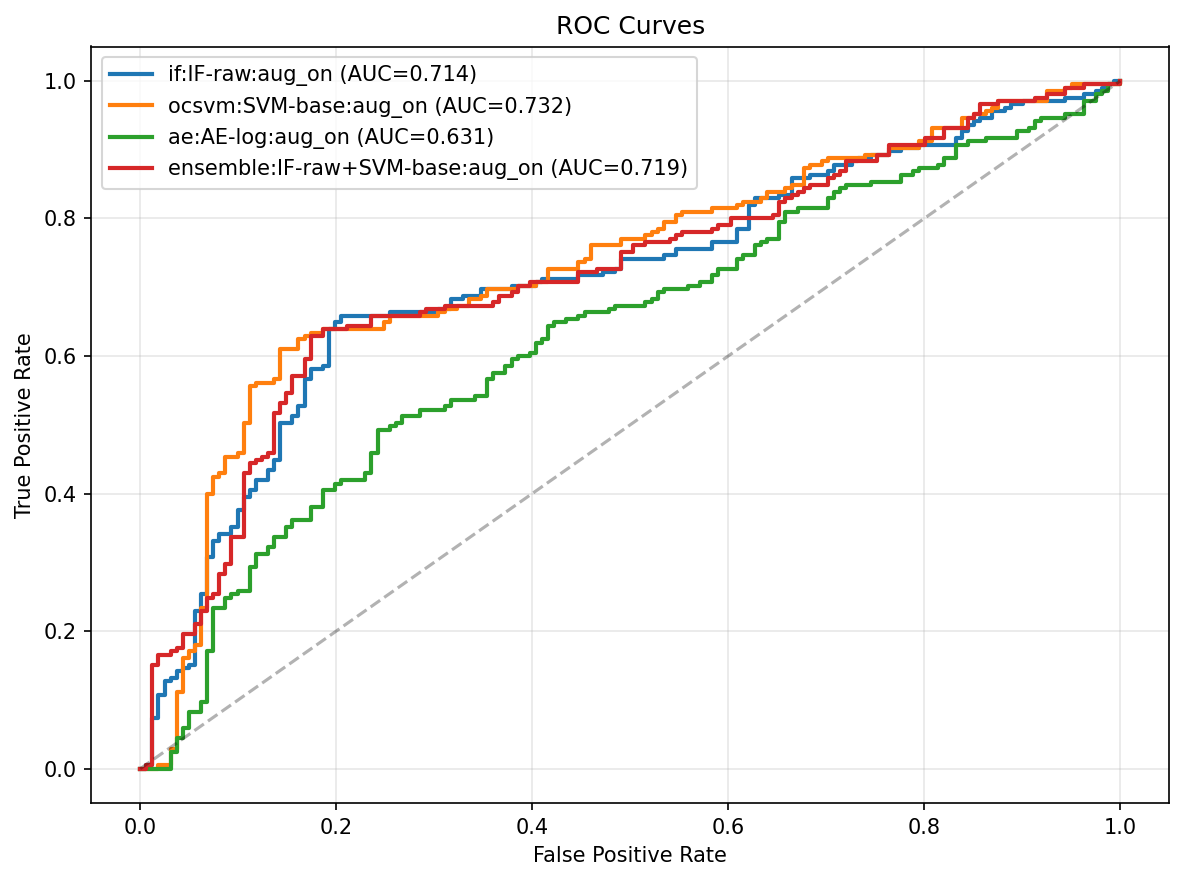

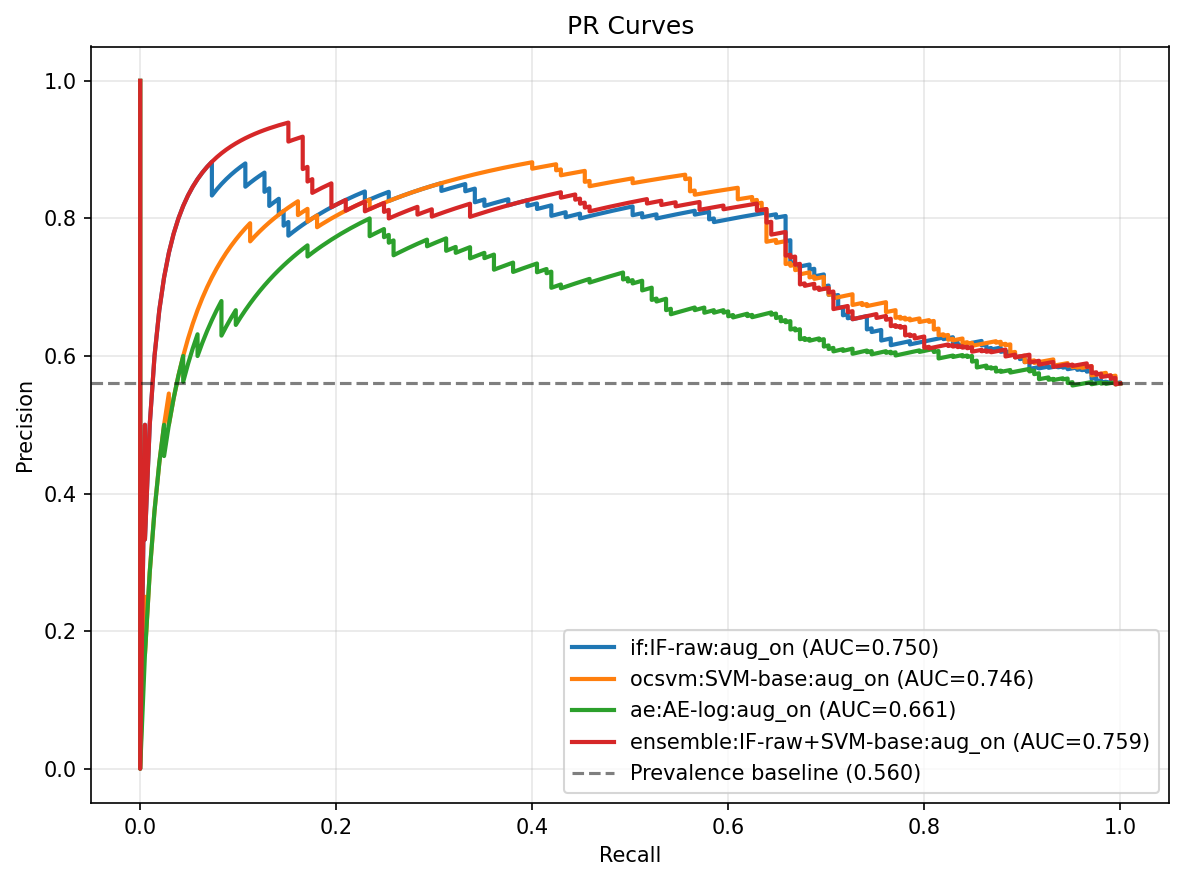

All final-report figures written under /home/amraas/projects/repoclones/CheatDetect/study/final_reports/figures


In [5]:
all_scores = {result["model"]: result["scores"] for result in results}
plot_roc_curves(all_scores, y_test, FIGURE_DIR / "roc_comparison.png")
plot_pr_curves(all_scores, y_test, FIGURE_DIR / "pr_comparison.png")
display(Image(filename=str(FIGURE_DIR / "roc_comparison.png")))
display(Image(filename=str(FIGURE_DIR / "pr_comparison.png")))
print(f"All final-report figures written under {FIGURE_DIR}")